# Sparse Regression, Text Classification and Exchange-Rate Forecasting

Three short applied machine-learning problems, each with a different lesson:

| Part | Problem | Approach | Headline |
|---|---|---|---|
| **1** | Which clinical measurements predict diabetes progression? | Iterative-thresholding least squares, written from scratch in NumPy | 2 of 10 features keep 89% of the full model's R² |
| **2** | Which of 20 topics is a forum post about? | k-NN baseline vs TF-IDF + logistic regression | Held-out accuracy 28% → **55%** |
| **3** | What will tomorrow's GBP/EUR and GBP/USD rates be? | Per-target linear regression with a walk-forward backtest | Beats a naive forecast by 44%, which **turned out to be a data artefact** |

Tools: NumPy, pandas, scikit-learn, matplotlib.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
BLUE, ORANGE, GREY = "#2563eb", "#f97316", "#9ca3af"

---
## Part 1: Sparse regression by iterative thresholding

Often we want a model that is accurate **and** uses few features, because it is cheaper to measure, easier to explain and less likely to overfit. LASSO is the standard tool. A simple alternative is **iterative thresholding**:

1. Fit ordinary least squares, $\min_w \|Xw - y\|_2^2$.
2. Drop features whose weight is smaller than a threshold $\tau$ in absolute value.
3. Refit on the remaining features and repeat until every weight is at least $\tau$.

I implement two variants with NumPy only:

* **`itls`** drops *every* feature below $\tau$ at each step, which is aggressive and fast.
* **`itls1`** drops only the *single smallest* one, then refits. This is more cautious, because a feature that looks weak now may become important once a correlated feature has been removed.

In [2]:
def itls(X, y, tau):
    n, d = X.shape
    kept = np.arange(d) # kept features

    while True:
        # least squares on the current features
        X_sub = X[:, kept]
        w_sub, _, _, _ = np.linalg.lstsq(X_sub, y, rcond = None)

        above = np.abs(w_sub) >= tau

        if np.all(above):
            break

        # keep only the features above the threshold
        kept = kept[above]

        # edge case: if no features remain, the model is all zeros
        if len(kept) == 0:
            return np.zeros(d)

    w = np.zeros(d)
    w[kept] = w_sub
    return w


def itls1(X, y, tau):
    n, d = X.shape
    kept = np.arange(d)

    while True:
        X_sub = X[:, kept]
        w_sub, _, _, _ = np.linalg.lstsq(X_sub, y, rcond = None)

        below = np.abs(w_sub) < tau

        # stop once no weight is below the threshold
        if not np.any(below):
            break

        # among those below the threshold, remove the one with the smallest |w|
        # (argmin returns the first index on ties, i.e. the smallest feature index)
        candidates = np.where(below)[0]
        smallest = candidates[np.argmin(np.abs(w_sub[candidates]))]

        kept = np.delete(kept, smallest)

        if len(kept) == 0:
            return np.zeros(d)

    w = np.zeros(d)
    w[kept] = w_sub
    return w

**Data.** scikit-learn's diabetes dataset has 442 patients and 10 baseline measurements: age, sex, BMI, blood pressure and six blood-serum readings `s1`–`s6`. The target is a measure of disease progression one year later. Features are z-score standardised so that weight sizes are comparable, which is what makes a single threshold $\tau$ meaningful.

**A detail that matters:** the model has no intercept term. Since the target averages about 152, fitting it raw forces the regression through zero and gives a *negative* R² for every $\tau$, worse than predicting the mean. Centring the target is equivalent to adding an intercept, so I fit on $y - \bar y$.

In [3]:
from sklearn import datasets

diabetes = datasets.load_diabetes(as_frame=True)["frame"]
feature_names = diabetes.drop("target", axis=1).columns
X = diabetes.drop("target", axis=1).values
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0) # z-normalise
y = diabetes["target"].values
y_c = y - y.mean()                               # centre target (≡ fitting an intercept)


def cod(y, y_hat):
    # coefficient of determination (R²)
    y_bar = np.mean(y)
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - y_bar) ** 2)
    return 1 - ss_res / ss_tot


w_full = np.linalg.lstsq(X, y_c, rcond=None)[0]
print(f"All 10 features, ordinary least squares: R² = {cod(y_c, X @ w_full):.3f}")
print(f"Same model on the uncentred target:      R² = {cod(y, X @ np.linalg.lstsq(X, y, rcond=None)[0]):.2f}")

All 10 features, ordinary least squares: R² = 0.518
Same model on the uncentred target:      R² = -3.39


In [4]:
taus = np.arange(5, 55, 5)

rows = []
for tau in taus:
    w0 = itls(X, y_c, tau)
    w1 = itls1(X, y_c, tau)
    rows.append({"tau": tau,
                 "itls": cod(y_c, X @ w0), "itls1": cod(y_c, X @ w1),
                 "features (itls)": int((w0 != 0).sum()), "features (itls1)": int((w1 != 0).sum()),
                 "itls1 keeps": ", ".join(feature_names[w1 != 0])})
results = pd.DataFrame(rows).set_index("tau")

CoD = results[["itls", "itls1"]]
results.round(3)

,itls,itls1,features (itls),features (itls1),itls1 keeps
tau,,,,,
5,0.516,0.517,7,8,"sex, bmi, bp, s1, s2, s3, s4, s5"
10,0.515,0.515,6,6,"sex, bmi, bp, s1, s2, s5"
15,0.476,0.476,4,4,"bmi, s1, s2, s5"
20,0.459,0.459,2,2,"bmi, s5"
25,0.320,0.459,1,2,"bmi, s5"
30,0.320,0.344,1,1,bmi
35,0.320,0.344,1,1,bmi
40,0.000,0.344,0,1,bmi
45,0.000,0.344,0,1,bmi


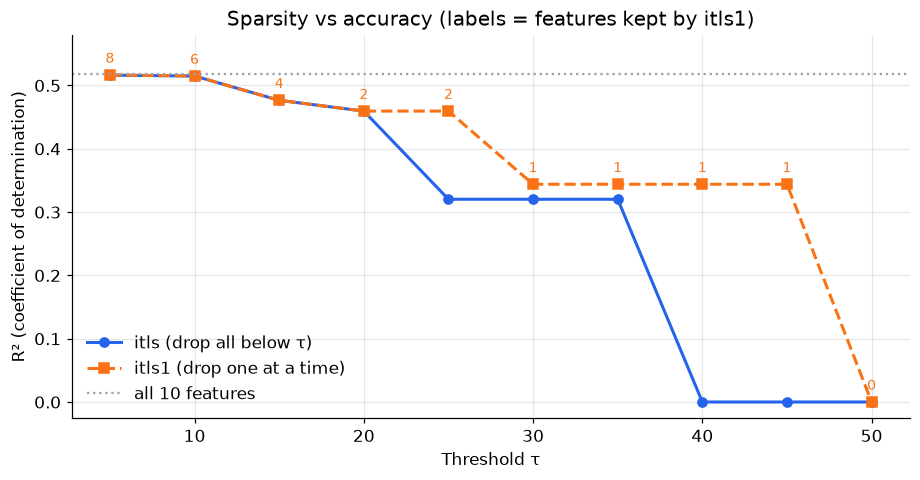

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(taus, results["itls"], marker="o", color=BLUE, lw=2, label="itls (drop all below τ)")
ax.plot(taus, results["itls1"], marker="s", color=ORANGE, lw=2, ls="--", label="itls1 (drop one at a time)")
ax.axhline(cod(y_c, X @ w_full), color=GREY, ls=":", label="all 10 features")
for tau in taus:
    ax.annotate(str(results.loc[tau, "features (itls1)"]), (tau, results.loc[tau, "itls1"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=ORANGE)
ax.set_ylim(top=0.58)
ax.set_xlabel("Threshold τ")
ax.set_ylabel("R² (coefficient of determination)")
ax.set_title("Sparsity vs accuracy (labels = features kept by itls1)")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

**Findings**

* **Most of the signal sits in two features.** At $\tau = 20$ both methods keep only **BMI and `s5`** (a blood-serum triglyceride measure) and reach R² = 0.459, which is **89% of the full 10-feature model's 0.518**.
* **Dropping one feature at a time is more robust.** At $\tau = 25$, `itls` throws away `s5` in the same step as other features and falls to R² = 0.32 with BMI alone. `itls1` refits after each removal, sees that `s5` has become strong, and keeps it. At $\tau = 40$–45 it still keeps BMI while `itls` has removed everything.
* This mirrors the classic trade-off between aggressive pruning and greedy backward elimination: the careful version costs more refits but does not discard features that only *look* weak while correlated features are still in the model.

---
## Part 2: Classifying forum posts into 20 topics

The **20 Newsgroups** corpus contains about 18,800 forum posts on 20 topics, from `sci.space` to `rec.sport.hockey`. Each post is turned into counts of the 500 most frequent words (of 3+ letters). The model must output a **probability for each of the 20 topics**, not just a single guess.

I train on the official training split (11,314 posts) and evaluate on the separate test split (7,532 posts, written *later*), which is a realistic check of generalisation. The corpus is downloaded and cached by scikit-learn the first time this runs.

In [6]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer

corpus, y_train = fetch_20newsgroups(return_X_y=True)
vectorizer = CountVectorizer(token_pattern=r"\b[a-zA-Z]{3,}\b", max_features=500)
X_train = vectorizer.fit_transform(corpus)
words = vectorizer.get_feature_names_out()
X_train = np.array(X_train.todense())

corpus_test, y_test = fetch_20newsgroups(subset="test", return_X_y=True)
X_test = np.array(vectorizer.transform(corpus_test).todense())

print(f"train {X_train.shape}, test {X_test.shape}")
print("sample vocabulary:", ", ".join(words[:12]), "…")

train (11314, 500), test (7532, 500)
sample vocabulary: able, about, above, access, actually, address, after, again, against, ago, agree, all …


The task needs a `predict` method that returns *probabilities*. scikit-learn classifiers expose these through `predict_proba`, so I wrap a pipeline in a small adapter class:

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, log_loss


class ProbaPipeLine:
    # adapter: .predict() returns class probabilities instead of labels
    def __init__(self, pipe):
        self.pipe = pipe

    def fit(self, X, y):
        self.pipe.fit(X, y)
        return self

    def predict(self, X):
        return self.pipe.predict_proba(X)


def evaluate(model, name):
    P = model.predict(X_test)
    return {"model": name,
            "train accuracy": accuracy_score(y_train, model.predict(X_train).argmax(axis=1)),
            "test accuracy": accuracy_score(y_test, P.argmax(axis=1)),
            "test log loss": log_loss(y_test, P, labels=range(20))}

### Baseline: k-nearest neighbours

In [8]:
pipe = Pipeline([
    ('scale', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

newspipe = ProbaPipeLine(pipe)
newspipe.fit(X_train, y_train)

knn_scores = evaluate(newspipe, "k-NN (k=5) on scaled counts")
pd.Series(knn_scores)

model             k-NN (k=5) on scaled counts
train accuracy                       0.658299
test accuracy                         0.27974
test log loss                       16.780825
dtype: object

At first sight the training accuracy of 66% looks reasonable, but **on unseen posts accuracy falls to 28%**. That is still well above the 5% from guessing, but the log loss of 16.8 is far worse than the 3.0 a uniform guess would score. Two problems:

* **Training accuracy flatters k-NN.** Each training post is its own nearest neighbour, so the model partly "remembers" the answer.
* **Overconfident probabilities.** With $k = 5$, every topic absent from the 5 neighbours gets probability **exactly 0**. When the true topic is one of them, log loss heavily penalises the confident mistake.

### Improvement: TF-IDF + logistic regression

Raw counts are dominated by common words ("the", "and", "that"), and distances in 500 dimensions become uninformative. **TF-IDF** down-weights words that appear in every post. **Logistic regression** learns a weight per word per topic and produces smooth, calibrated probabilities. Same 500 features, same adapter:

In [9]:
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression

newspipe_lr = ProbaPipeLine(Pipeline([
    ("tfidf", TfidfTransformer()),
    ("logreg", LogisticRegression(C=10, max_iter=2000)),
])).fit(X_train, y_train)

comparison = pd.DataFrame([knn_scores, evaluate(newspipe_lr, "TF-IDF + logistic regression")]).set_index("model")
comparison.round(3)

,train accuracy,test accuracy,test log loss
model,,,
k-NN (k=5) on scaled counts,0.658,0.280,16.781
TF-IDF + logistic regression,0.830,0.555,1.509


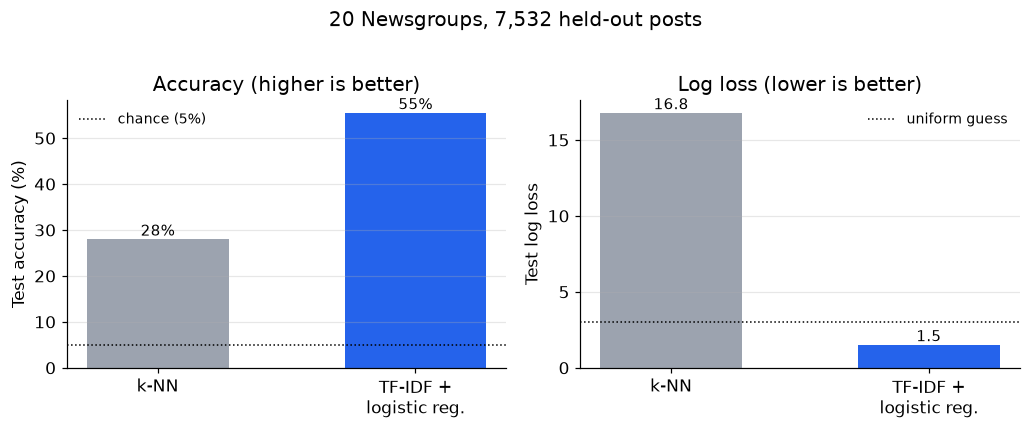

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
names = ["k-NN", "TF-IDF +\nlogistic reg."]
axes[0].bar(names, comparison["test accuracy"] * 100, color=[GREY, BLUE], width=0.55)
axes[0].axhline(5, color="black", ls=":", lw=1, label="chance (5%)")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_title("Accuracy (higher is better)")
axes[1].bar(names, comparison["test log loss"], color=[GREY, BLUE], width=0.55)
axes[1].axhline(np.log(20), color="black", ls=":", lw=1, label="uniform guess")
axes[1].legend(frameon=False, loc="upper right", fontsize=9)
axes[1].set_ylabel("Test log loss")
axes[1].set_title("Log loss (lower is better)")
for ax, col, fmt in [(axes[0], "test accuracy", "{:.0%}"), (axes[1], "test log loss", "{:.1f}")]:
    ax.grid(axis="x", visible=False)
    for i, v in enumerate(comparison[col]):
        ax.text(i, v * (100 if col == "test accuracy" else 1), fmt.format(v), ha="center", va="bottom", fontsize=10)
fig.suptitle("20 Newsgroups, 7,532 held-out posts", y=1.02)
plt.tight_layout()
plt.show()

**Accuracy roughly doubles (28% → 55%) and log loss falls elevenfold (16.8 → 1.5)**, with the same features and less than a second of training. The remaining gap comes from the tiny 500-word vocabulary. A full vocabulary with stop-word removal would be the next step.

---
## Part 3: Forecasting tomorrow's exchange rates

**Data:** daily GBP→EUR and GBP→USD rates (Open, High, Low, Close) from 2003 to April 2025, about 5,500 trading days with both series available.

**Task:** write `train_models(rates_t)`, which trains on any historical window of at least 500 days, and `predict_rates(models, rates_h)`, which predicts all eight values for the **next** trading day using only information up to the last day in `rates_h`.

In [11]:
eur = pd.read_csv("data/gbp-eur2.csv", index_col="Date")
usd = pd.read_csv("data/gbp-usd2.csv", index_col="Date")
rates = pd.concat([eur, usd], axis=1, keys=["EUR", "USD"])
rates.columns = ["_".join(col).strip() for col in rates.columns.values]
rates = rates.dropna()
rates.tail()

,EUR_Close,EUR_High,EUR_Low,EUR_Open,USD_Close,USD_High,USD_Low,USD_Open
Date,,,,,,,,
2025-04-07,1.17519,1.17802,1.16548,1.17519,1.291072,1.293360,1.272281,1.291239
2025-04-08,1.16651,1.17191,1.16353,1.16651,1.273496,1.279591,1.272653,1.273885
2025-04-09,1.16462,1.16489,1.15434,1.16462,1.279100,1.286058,1.275396,1.278756
2025-04-10,1.17102,1.17361,1.15566,1.17102,1.282545,1.297825,1.282429,1.282676
2025-04-11,1.15393,1.15521,1.14433,1.15393,1.299207,1.314285,1.298752,1.299427


**Model.** For each of the eight targets I fit a linear regression on all eight values from the previous day.

In [12]:
from sklearn.linear_model import LinearRegression


def train_models(rates_t):
    # features: day t; target: day t+1
    X = rates_t.iloc[:-1].values
    Y = rates_t.iloc[1:].values

    models = {}
    target_cols = rates_t.columns.tolist()

    for i, col in enumerate(target_cols):
        lm = LinearRegression()
        lm.fit(X, Y[:, i])
        models[col] = lm

    return models


def predict_rates(models, rates_h):
    x = rates_h.iloc[[-1]].values
    target_cols = ['EUR_Close', 'EUR_High', 'EUR_Low', 'EUR_Open',
                   'USD_Close', 'USD_High', 'USD_Low', 'USD_Open']
    predictions = [models[col].predict(x)[0] for col in target_cols]
    return predictions

In [13]:
# train on 2017–2023, then predict the next trading day after 9 Aug 2024
models = train_models(rates.loc["2017-01-01":"2023-12-31"])
rates_h = rates.loc["2024-01-01":"2024-08-09"]
dict(zip(rates.columns, np.round(predict_rates(models, rates_h), 4)))

{'EUR_Close': np.float64(1.1676),
 'EUR_High': np.float64(1.1703),
 'EUR_Low': np.float64(1.1644),
 'EUR_Open': np.float64(1.1676),
 'USD_Close': np.float64(1.2753),
 'USD_High': np.float64(1.2791),
 'USD_Low': np.float64(1.2711),
 'USD_Open': np.float64(1.2753)}

### Walk-forward backtest

A forecast only means something next to a baseline. For exchange rates the standard one is **persistence**: tomorrow's value equals today's (a random walk). I train once on 2017–2023, then step through every trading day from January 2024 to April 2025. Each day I predict from data up to the previous day only, so nothing from the future leaks in.

In [14]:
history = rates.loc["2017-01-01":]
start = history.index.get_loc(rates.loc["2024-01-01":].index[0])

preds, actual, persistence = [], [], []
for t in range(start, len(history)):
    preds.append(predict_rates(models, history.iloc[t - 50:t]))
    actual.append(history.iloc[t].values)
    persistence.append(history.iloc[t - 1].values)

preds, actual, persistence = map(np.array, (preds, actual, persistence))
backtest = pd.DataFrame({
    "model MAE": np.abs(preds - actual).mean(axis=0),
    "persistence MAE": np.abs(persistence - actual).mean(axis=0),
}, index=rates.columns)
backtest["improvement"] = 1 - backtest["model MAE"] / backtest["persistence MAE"]

print(f"{len(actual)} out-of-sample trading days (improvement > 0 means the model beats persistence)")
backtest.style.format({"model MAE": "{:.5f}", "persistence MAE": "{:.5f}", "improvement": "{:+.0%}"})

334 out-of-sample trading days (improvement > 0 means the model beats persistence)


,model MAE,persistence MAE,improvement
EUR_Close,0.00138,0.00246,+44%
EUR_High,0.00185,0.00211,+12%
EUR_Low,0.00252,0.00210,-20%
EUR_Open,0.00138,0.00245,+44%
USD_Close,0.00229,0.00416,+45%
USD_High,0.00322,0.00373,+14%
USD_Low,0.00363,0.00366,+1%
USD_Open,0.00229,0.00415,+45%


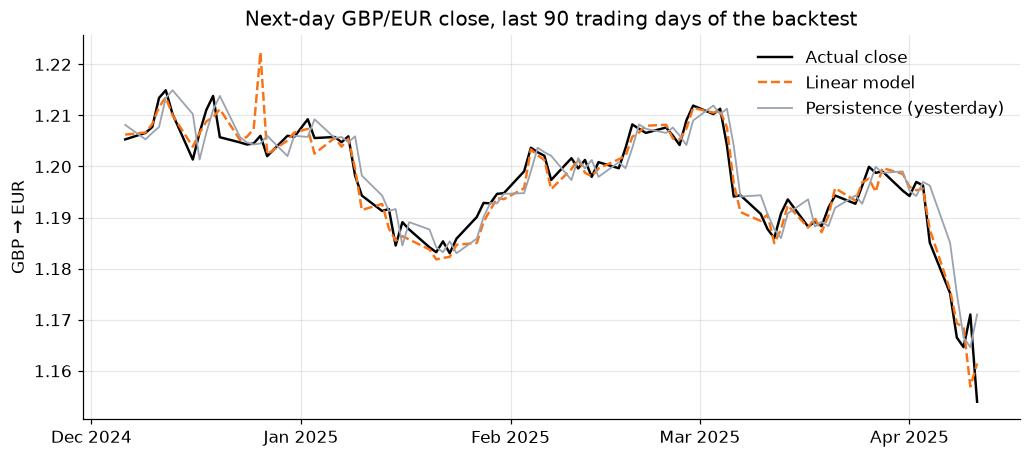

In [15]:
import matplotlib.dates as mdates

test_dates = pd.to_datetime(history.index[start:])
last = slice(-90, None)

fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(test_dates[last], actual[last, 0], color="black", lw=1.6, label="Actual close")
ax.plot(test_dates[last], preds[last, 0], color=ORANGE, lw=1.6, ls="--", label="Linear model")
ax.plot(test_dates[last], persistence[last, 0], color=GREY, lw=1.2, label="Persistence (yesterday)")
ax.set_ylabel("GBP → EUR")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_title("Next-day GBP/EUR close, last 90 trading days of the backtest")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Too good to be true? Investigating the edge

The model is **44% more accurate than persistence** for the closing rate. For a major currency pair that should be close to impossible, since FX markets are highly efficient. A result like this calls for scrutiny, not celebration. The fitted coefficients show where the "edge" comes from:

In [16]:
coef = pd.Series(models["EUR_Close"].coef_, index=rates.columns)
print("Tomorrow's EUR_Close ≈")
print(coef[coef.abs() > 0.05].round(2).to_string())
print(f"\nDays on which recorded Open == Close: {(rates['EUR_Open'] == rates['EUR_Close']).mean():.0%}")

Tomorrow's EUR_Close ≈
EUR_High     0.81
EUR_Low      0.77
EUR_Open    -0.54
USD_Close    0.14
USD_Open    -0.19

Days on which recorded Open == Close: 22%


* The prediction leans on **yesterday's High and Low**, not yesterday's Close.
* On **22% of days the recorded Open exactly equals the Close**, which genuine daily open and close prices would almost never do.

Together these suggest the "Close" in this data is **a snapshot taken early in the trading day**, while High and Low cover the full session. So the High and Low already contain part of the move that the *next* row's "Close" records. The model is exploiting **a timing quirk in the data**, not predicting the market. With correctly time-stamped closes I would expect the edge to disappear. Tellingly, the model already fails to beat persistence on the Low columns (−20% for EUR, +1% for USD).

**Lesson:** a backtest is only as honest as the timestamps behind it. Before trusting a forecasting edge, check exactly *when* each feature is observed.

---
## Summary

| | Result | Takeaway |
|---|---|---|
| **Sparse regression** | BMI + `s5` give R² 0.46, against 0.52 with all 10 features | Refitting after each removal (`itls1`) keeps useful correlated features that one-shot thresholding discards |
| **Text classification** | Held-out accuracy 28% → 55%, log loss 16.8 → 1.5 | Judge on held-out data with a proper probabilistic score. Training accuracy and hard k-NN votes hide the problem |
| **FX forecasting** | 44% lower MAE than persistence on closing rates | A suspiciously large edge, traced to the data's timestamps rather than real predictability |